# IMC-HistoTools tutorial 2: pix H-Score classification, proportions, and visualization

Pipeline: `virtual_IHC_annotation` → `Hscore_threshold` → pixel-wise classification → two plotting functions:

- `pix_Hscore_plot_map`: pixel-wise classification color map (map)
- `pix_Hscore_plot_bar`: per-region pix H-score bar chart + NP/LP/MP/HP proportion table

> Note: the former all-in-one `pix_Hscore_map` has been removed; the workflow is now "classify / compute yourself + plot separately".


In [1]:
import os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tifffile

# ---- Load the IMC_HistoTools package (repository root) ----
IMC_HistoTools_path = "/Users/gjhan/Documents/GitHub/Whole-Slide_IMC"
if IMC_HistoTools_path not in sys.path:
    sys.path.insert(0, IMC_HistoTools_path)

import IMC_HistoTools
from IMC_HistoTools import (
    virtual_IHC, virtual_IHC_ROI,
    virtual_IHC_annotation, Hscore_threshold,
    pix_Hscore_plot_map, pix_Hscore_plot_bar,
    SCORE_COLORS, BAR_ORDER,
)

out_dir = Path("/Users/gjhan/Documents/Papers_submit/Selenium/Data/261107_IMC_HistoTools")
out_dir.mkdir(parents=True, exist_ok=True)

print("IMC_HistoTools version:", IMC_HistoTools.__version__)
print("output dir:", out_dir)


IMC_HistoTools version: 0.1.0
output dir: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261107_IMC_HistoTools


## 1. Load IMC channels and tissue mask


In [2]:
CRC = Path("/Users/gjhan/Documents/Papers_submit/Selenium/Data/260927_virIHC/260923_yr-CRC_Ecad_2TSA")

Se_Ecadherin = tifffile.imread(CRC / "Normalize/ROI_001_Se_crop_normal.tiff").astype(np.float32)
DNA_CRC1     = tifffile.imread(CRC / "Normalize/ROI_001_191Ir-DNA191_Ir191_crop_normal.tiff").astype(np.float32)
DNA_CRC2     = tifffile.imread(CRC / "Normalize/ROI_001_193Ir-DNA193_Ir193_crop_normal.tiff").astype(np.float32)
mask         = tifffile.imread(CRC / "Mask/CRC_TM_mask_crop.tiff")
tissue       = mask > 0

geojson_path = Path("/Users/gjhan/Documents/Papers_submit/Selenium/Data/261003_Qpath/CRC_TM_raw_261003.geojson")
ref_geojson  = Path("/Users/gjhan/Documents/Papers_submit/Selenium/Data/261013_IMC_HistoTools/261013_CRC_virtual_IHC_raw.geojson")

print("Se_Ecadherin :", Se_Ecadherin.shape)
print("tissue px    :", int(tissue.sum()), f"({100*tissue.mean():.1f}%)")
print("geojson      :", geojson_path.exists())


Se_Ecadherin : (2531, 3420)
tissue px    : 4535468 (52.4%)
geojson      : True


## 2. Tissue-region ROIs (Tumor center / Normal mucosa / Satellites / Invasive front)

`virtual_IHC_annotation` reads only `Low / Medium / High` by default; pass `regions=None` to read tissue regions.


In [3]:
annotation = virtual_IHC_annotation(Se_Ecadherin, geojson_path, regions=None)

print("regions:", annotation["names"])
for n in annotation["names"]:
    print(f"  {n:16s}: area = {int(annotation['masks'][n].sum()):,} px")

region_masks = annotation["masks"]


regions: ['Normal mucosa', 'Tumor center', 'Satellites', 'Invasive front']
  Normal mucosa   : area = 444,879 px
  Tumor center    : area = 1,510,423 px
  Satellites      : area = 60,046 px
  Invasive front  : area = 483,058 px


## 3. Reference ROIs → level thresholds (Low / Medium / High)

The reference geojson contains Negative / Low / Medium / High. This version reads only `Low / Medium / High` (Negative is not used).


In [4]:
ref = virtual_IHC_annotation(Se_Ecadherin, ref_geojson)   # default: Low/Medium/High

print("reference ROI regions:", ref["names"])
for n in ref["names"]:
    print(f"  {n:10s}: {len(ref['polys'][n])} polygon(s), area = {int(ref['masks'][n].sum()):,} px")

Lp = ref["masks"]["Low"]
Mp = ref["masks"]["Medium"]
Hp = ref["masks"]["High"]

thr = Hscore_threshold(Se_Ecadherin, Lp=Lp, Mp=Mp, Hp=Hp, tissue_mask=tissue, stat="median")
for k in ("Lp", "Mp", "Hp"):
    s = thr[k]
    print(f"  {k:3s}: mean={s['mean']:.4f}  median={s['median']:.4f}  "
          f"geomean={s['geomean']:.4f}  all={s['all']:.4f}")
print("thresholds (median, Lp/Mp/Hp):", tuple(round(t, 4) for t in thr["thresholds"]))


reference ROI regions: ['Low', 'Medium', 'High']
  Low       : 5 polygon(s), area = 12,549 px
  Medium    : 7 polygon(s), area = 11,851 px
  High      : 4 polygon(s), area = 6,535 px
  Lp : mean=0.1512  median=0.1430  geomean=0.1359  all=0.1434
  Mp : mean=0.2518  median=0.2399  geomean=0.2317  all=0.2411
  Hp : mean=0.3878  median=0.3691  geomean=0.3588  all=0.3719
thresholds (median, Lp/Mp/Hp): (0.143, 0.2399, 0.3691)


## 4. Pixel-wise classification and per-region statistics

Classification rule: `<T1→0(NP)`, `[T1,T2)→1(LP)`, `[T2,T3)→2(MP)`, `≥T3→3(HP)`.
pix H-score = `100 × (3·HP + 2·MP + 1·LP) / total`.


In [5]:
T1, T2, T3 = thr["thresholds"]
scores = np.select(
    [Se_Ecadherin >= T3, Se_Ecadherin >= T2, Se_Ecadherin >= T1],
    [3, 2, 1], default=0,
).astype(np.uint8)


def region_pix_hscore(region_mask):
    sc = scores[region_mask]
    total = int(sc.size)
    counts = {k: int((sc == k).sum()) for k in (0, 1, 2, 3)}
    pix_h = 100.0 * (3 * counts[3] + 2 * counts[2] + counts[1]) / total if total else 0.0
    percents = {k: (100.0 * v / total if total else 0.0) for k, v in counts.items()}
    return {"pix_h": pix_h, "counts": counts, "percents": percents,
            "total": total, "valid_px": int(region_mask.sum())}


# per-region statistics (ROI ∩ tissue)
results = {n: region_pix_hscore(region_masks[n] & tissue) for n in region_masks}
for n, r in results.items():
    print(f"{n:16s} pix H-score = {r['pix_h']:6.1f}   (valid px = {r['valid_px']:,})")


Normal mucosa    pix H-score =   61.5   (valid px = 435,962)
Tumor center     pix H-score =   86.3   (valid px = 1,496,337)
Satellites       pix H-score =   43.8   (valid px = 59,712)
Invasive front   pix H-score =   14.6   (valid px = 483,048)


## 5. Example A — classification color map `pix_Hscore_plot_map`

Can be called independently: pass the marker image + thresholds. Common parameters:

- `blur_sigma` / `blur_kernel`: Gaussian blur before display (default `5` / `(7, 7)`)
- `grid` / `grid_linewidth`: grid on/off and line width
- `spine_linewidth`: axis spine line width


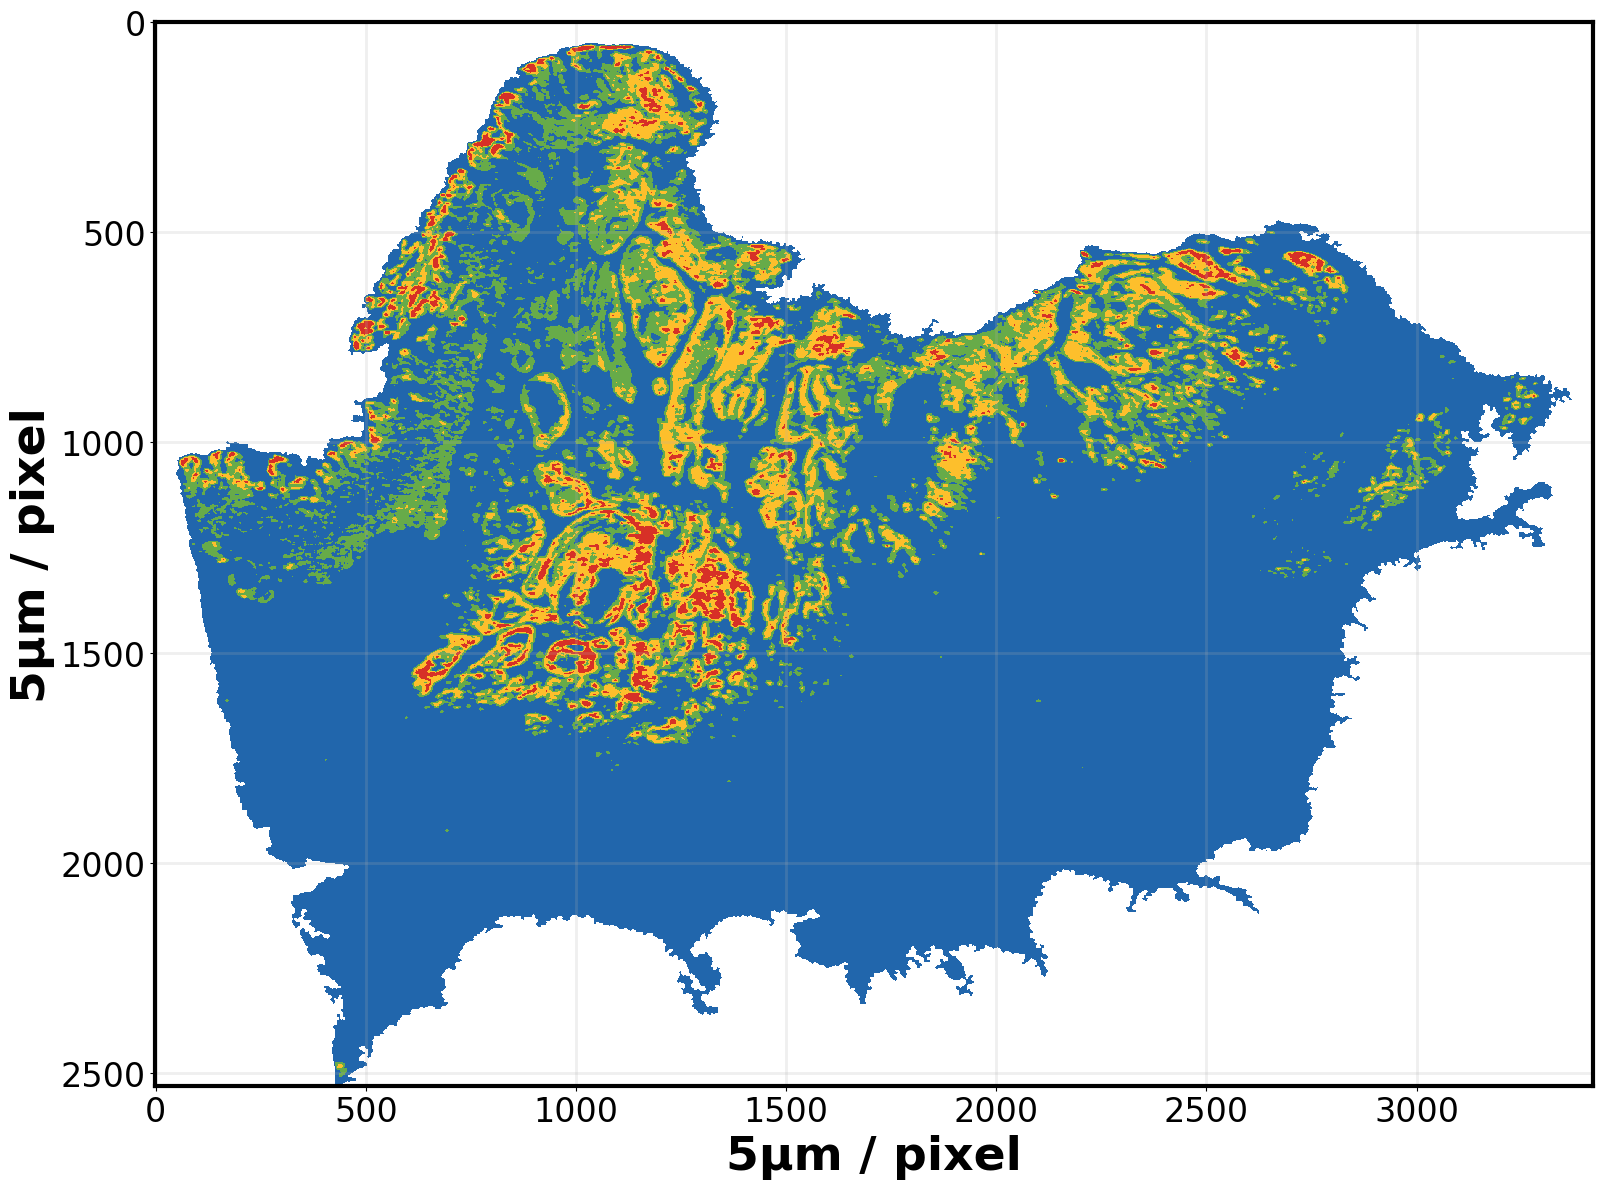

In [23]:
fig_map = pix_Hscore_plot_map(
    Se_Ecadherin,
    thr["thresholds"],              # (T1, T2, T3) = (Lp, Mp, Hp)
    tissue_mask=tissue,             # set background to white
    blur_sigma=5,
    blur_kernel=(7, 7),
    grid=True,
    colorbar=False,
    grid_linewidth=2.0,
    spine_linewidth=3.0,
    figsize=(18, 12),
    xlabel="5μm / pixel",
    ylabel="5μm / pixel",
    save_path=str(out_dir / "CRC_T2_map_example.png"),
    dpi=200,
    show=True,
)


## 6. Example B — bar chart + table `pix_Hscore_plot_bar`

Input `results` (computed above, or constructed manually). Bar order is controlled by `BAR_ORDER`:
`['Tumor center', 'Normal mucosa', 'Satellites', 'Invasive front']`

The title is controlled by `bar_title` (default `"pix H-scores"`) + `bar_title_pad` (replacing the y-axis label); all font sizes are adjustable: `title_fontsize` / `title_fontweight`, `tick_fontsize` / `tick_fontweight`, `value_fontsize`, `table_fontsize`, `overall_fontsize`.


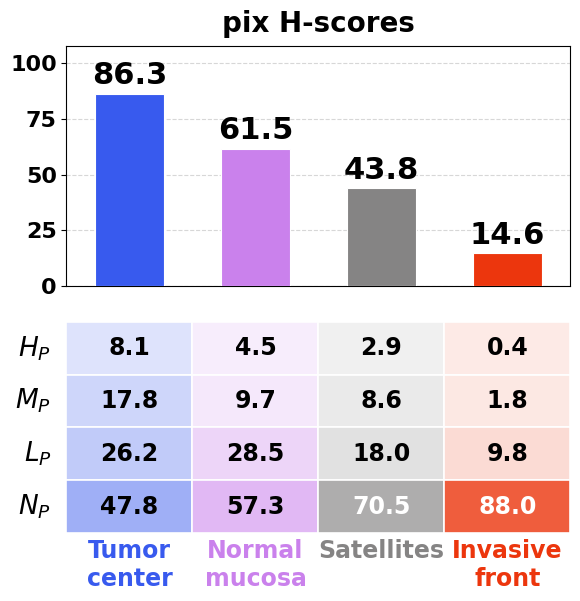

In [21]:
fig_bar = pix_Hscore_plot_bar(
    results,
    bar_order=BAR_ORDER,
    figsize=(6, 6),
    bar_title="pix H-scores", bar_title_pad=10,
    title_fontsize=20, title_fontweight="bold",
    tick_fontsize=16, tick_fontweight="bold",
    value_fontsize=22,
    table_fontsize=17,
    overall_fontsize=12,
    overall_hscore=None,             # pass the overall tissue pix H-score to draw a reference line
    save_path=str(out_dir / "CRC_T2_bar_example.png"),
    dpi=200,
    show=True,
)
